In [1]:
# Ensure we can import from our 'src' package
import sys
import os

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Now import our simulated device and detector
from src.simulated_display import SimulatedLEDDisplay # Still good to have this if you want to use the base class
from src.simulated_detector import SimulatedParticleDetector # Our new detector!

import matplotlib.pyplot as plt
import numpy as np

# Set up matplotlib for inline display
%matplotlib inline
plt.rcParams['figure.figsize'] = (6, 6) # Adjust figure size for better visualization

In [2]:
detector_width = 32 # Let's make it a bit larger for events
detector_height = 32

# Initialize with a dark background to simulate a 'cold' detector
my_detector = SimulatedParticleDetector(detector_width, detector_height, initial_background=(10, 10, 10))

print(f"Detector Firmware Version: {my_detector.get_firmware_version()}")
print(f"Max energy per pixel: {my_detector.max_energy_per_pixel}")

SimulatedLEDDisplay initialized: 32x32 pixels.
Hardware boot sequence complete.
SimulatedParticleDetector initialized: 32x32 cells.
Detector Firmware Version: v1.0.0-alpha
Max energy per pixel: 255


Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (16.0,16.0) with peak brightness 2000, radius 10.0
Retrieving display data...
Total deposited energy read: 75765


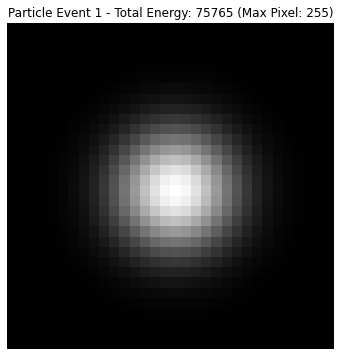

In [6]:
my_detector.clear_display() # Start with a clean slate

# Simulate a particle hitting near the center with a desired peak brightness and spread
# Now, peak_brightness_contribution directly controls the max pixel value (0-255)
my_detector.simulate_particle_hit(
    impact_x=detector_width / 2,
    impact_y=detector_height / 2,
    peak_brightness_contribution=2000, # A high value, but not fully saturating 255
    spread_radius=10.0 # Slightly reduced radius for better visualization on a 32x32 grid
)

# Get and visualize the event
event_data = my_detector.get_display_data()
total_energy = my_detector.get_total_deposited_energy()
max_pixel_val = my_detector.get_max_pixel_value()

plt.imshow(event_data)
plt.title(f"Particle Event 1 - Total Energy: {total_energy:.0f} (Max Pixel: {max_pixel_val})")
plt.axis('off')
plt.show()

Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (10.0,10.0) with peak brightness 80, radius 3.0
Simulating particle hit at (25.0,5.0) with peak brightness 180, radius 7.0
Simulating particle hit at (8.0,28.0) with peak brightness 120, radius 4.0
Adding background noise with max level: 10
Retrieving display data...
Total deposited energy read: 48428


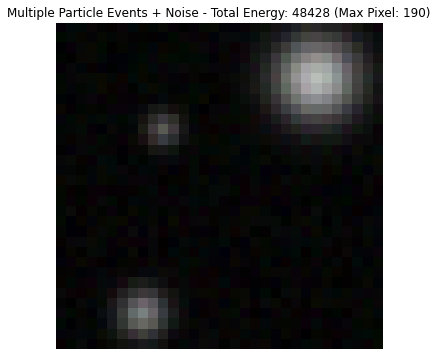

Performing hardware reset...
Hardware reset complete.


In [9]:
my_detector.clear_display() # Clear for a new event

# Simulate a few more hits in different locations with varying peak brightness contributions
my_detector.simulate_particle_hit(10, 10, 80, 3.0)  # Moderate peak brightness
my_detector.simulate_particle_hit(25, 5, 180, 7.0) # High peak brightness, larger spread
my_detector.simulate_particle_hit(8, 28, 120, 4.0) # Medium peak brightness

# Add some background noise (might need to tune this down if it's still too dominant)
my_detector.add_background_noise(noise_level=10, seed=42) # Try noise_level=10 or 5

event_data = my_detector.get_display_data()
total_energy = my_detector.get_total_deposited_energy()
max_pixel_val = my_detector.get_max_pixel_value()

plt.imshow(event_data)
plt.title(f"Multiple Particle Events + Noise - Total Energy: {total_energy:.0f} (Max Pixel: {max_pixel_val})")
plt.axis('off')
plt.show()

# Simulate a hardware reset at the end of an acquisition period
my_detector.reset_hardware()

### Section: Event Data Generation for ML ###

In [11]:
# Configure Dataset Generation Parameters
#define how many events we want, where to save them, and the characteristics of our simulated particles/noise.

# --- Dataset Configuration ---
NUM_EVENTS = 1000  # Total number of simulated events to generate
DATASET_DIR = "simulated_events" # Directory to save the events

# --- Detector Configuration (should match your initialization in previous cells) ---
detector_width = 32
detector_height = 32

# --- Particle Hit Parameters (ranges for randomization) ---
MIN_BRIGHTNESS = 50   # Min peak brightness for a particle hit
MAX_BRIGHTNESS = 250  # Max peak brightness for a particle hit (capped at 255)
MIN_RADIUS = 2.0      # Min spread radius for a particle hit
MAX_RADIUS = 8.0      # Max spread radius for a particle hit

# --- Noise Parameters ---
NOISE_LEVEL_RANGE = (5, 20) # Min and Max noise level to apply per event

# --- Event Type Probabilities ---
# Define the probability for different types of events
# This creates a dataset that the NN might later learn to classify
PROB_SINGLE_HIT = 0.6  # Probability of a single particle hit event
PROB_DOUBLE_HIT = 0.2  # Probability of a two-particle hit event
PROB_NOISE_ONLY = 0.2  # Probability of only noise (no particle hit)

# Create the directory if it doesn't exist
import os
if not os.path.exists(DATASET_DIR):
    os.makedirs(DATASET_DIR)
    print(f"Created directory: {DATASET_DIR}")
else:
    print(f"Directory already exists: {DATASET_DIR}")

# (Re)Initialize detector for clean data generation
my_detector = SimulatedParticleDetector(detector_width, detector_height, initial_background=(10, 10, 10))
print("Detector re-initialized for data generation.")

Directory already exists: simulated_events
SimulatedLEDDisplay initialized: 32x32 pixels.
Hardware boot sequence complete.
SimulatedParticleDetector initialized: 32x32 cells.
Detector re-initialized for data generation.


In [12]:
#  Generate and Save Events

import random # For randomizing event parameters

event_data_list = [] # Optional: to keep some events in memory for quick visualization

print(f"Generating {NUM_EVENTS} simulated events...")

for i in range(NUM_EVENTS):
    my_detector.clear_display() # Start each event with a clean detector
    
    event_label = {} # Dictionary to store ground truth labels for this event
    
    # Decide event type based on probabilities
    event_type_choice = random.choices(
        ['single_hit', 'double_hit', 'noise_only'],
        weights=[PROB_SINGLE_HIT, PROB_DOUBLE_HIT, PROB_NOISE_ONLY],
        k=1
    )[0]
    
    event_label['type'] = event_type_choice
    event_label['impacts'] = [] # List to store details of each particle hit

    if event_type_choice == 'single_hit':
        # Simulate one particle hit
        impact_x = random.uniform(0, detector_width)
        impact_y = random.uniform(0, detector_height)
        brightness = random.randint(MIN_BRIGHTNESS, MAX_BRIGHTNESS)
        radius = random.uniform(MIN_RADIUS, MAX_RADIUS)
        
        my_detector.simulate_particle_hit(impact_x, impact_y, brightness, radius)
        
        event_label['impacts'].append({
            'x': impact_x, 'y': impact_y, 'brightness': brightness, 'radius': radius
        })
        
    elif event_type_choice == 'double_hit':
        # Simulate two particle hits
        for _ in range(2):
            impact_x = random.uniform(0, detector_width)
            impact_y = random.uniform(0, detector_height)
            brightness = random.randint(MIN_BRIGHTNESS, MAX_BRIGHTNESS)
            radius = random.uniform(MIN_RADIUS, MAX_RADIUS)
            
            my_detector.simulate_particle_hit(impact_x, impact_y, brightness, radius)
            
            event_label['impacts'].append({
                'x': impact_x, 'y': impact_y, 'brightness': brightness, 'radius': radius
            })

    # Always add some noise (randomly chosen level)
    current_noise_level = random.randint(*NOISE_LEVEL_RANGE)
    my_detector.add_background_noise(noise_level=current_noise_level, seed=i) # Using 'i' as seed for variety
    event_label['noise_level'] = current_noise_level

    # Get the final detector state (image)
    event_image_data = my_detector.get_display_data()
    event_label['total_energy_read'] = my_detector.get_total_deposited_energy()
    event_label['max_pixel_value'] = my_detector.get_max_pixel_value()

    # Save the event: image and labels
    # Use f-string to create a unique filename for each event
    file_path = os.path.join(DATASET_DIR, f"event_{i:05d}.npz") # e.g., event_00001.npz
    np.savez_compressed(file_path, image=event_image_data, labels=event_label)
    
    # Optionally, store a few examples in memory for immediate display
    if i < 5 or i % (NUM_EVENTS // 10) == 0: # Store first 5 and then every 10%
        event_data_list.append((event_image_data, event_label))

    if (i + 1) % (NUM_EVENTS // 10) == 0: # Print progress
        print(f"Generated {i + 1}/{NUM_EVENTS} events.")

print("Event generation complete!")
print(f"Saved events to '{DATASET_DIR}' directory.")

Generating 1000 simulated events...
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (2.9,14.1) with peak brightness 134, radius 5.4
Adding background noise with max level: 7
Retrieving display data...
Total deposited energy read: 21559
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (23.1,25.1) with peak brightness 181, radius 3.0
Adding background noise with max level: 18
Retrieving display data...
Total deposited energy read: 32211
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (23.8,16.5) with peak brightness 118, radius 7.7
Adding background noise with max level: 14
Retrieving display data...
Total deposited energy read: 41983
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (17.4,5.7) with peak brightness 154, radius 4.9
Adding background noise with max level: 8
Retrieving display data...
Total deposited energy read: 23163
Display filled with color: (

Adding background noise with max level: 5
Retrieving display data...
Total deposited energy read: 15898
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (3.3,14.4) with peak brightness 77, radius 5.2
Adding background noise with max level: 11
Retrieving display data...
Total deposited energy read: 22655
Display filled with color: (0, 0, 0)
Display cleared.
Adding background noise with max level: 11
Retrieving display data...
Total deposited energy read: 16846
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (18.2,23.5) with peak brightness 89, radius 5.1
Simulating particle hit at (23.9,9.7) with peak brightness 238, radius 5.3
Adding background noise with max level: 16
Retrieving display data...
Total deposited energy read: 50989
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (29.1,5.2) with peak brightness 215, radius 3.8
Adding background noise with max level: 16
Retrieving display data

Adding background noise with max level: 11
Retrieving display data...
Total deposited energy read: 29843
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (12.5,7.0) with peak brightness 88, radius 6.6
Adding background noise with max level: 12
Retrieving display data...
Total deposited energy read: 29817
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (10.9,10.3) with peak brightness 152, radius 4.5
Adding background noise with max level: 19
Retrieving display data...
Total deposited energy read: 38294
Display filled with color: (0, 0, 0)
Display cleared.
Adding background noise with max level: 17
Retrieving display data...
Total deposited energy read: 26266
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (3.0,6.3) with peak brightness 166, radius 2.3
Adding background noise with max level: 10
Retrieving display data...
Total deposited energy read: 18044
Display filled with color: (0, 0, 0

Display cleared.
Simulating particle hit at (17.5,19.8) with peak brightness 248, radius 2.0
Simulating particle hit at (24.8,2.5) with peak brightness 144, radius 7.9
Adding background noise with max level: 10
Retrieving display data...
Total deposited energy read: 39772
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (21.1,6.7) with peak brightness 229, radius 7.5
Adding background noise with max level: 6
Retrieving display data...
Total deposited energy read: 46964
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (24.4,10.1) with peak brightness 191, radius 2.5
Adding background noise with max level: 14
Retrieving display data...
Total deposited energy read: 24990
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (10.1,25.6) with peak brightness 64, radius 6.1
Adding background noise with max level: 8
Retrieving display data...
Total deposited energy read: 19087
Display filled with color:

Adding background noise with max level: 13
Retrieving display data...
Total deposited energy read: 34410
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (6.3,30.1) with peak brightness 91, radius 6.3
Adding background noise with max level: 12
Retrieving display data...
Total deposited energy read: 26612
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (6.2,0.5) with peak brightness 102, radius 5.3
Adding background noise with max level: 11
Retrieving display data...
Total deposited energy read: 22517
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (2.9,14.5) with peak brightness 238, radius 7.2
Adding background noise with max level: 10
Retrieving display data...
Total deposited energy read: 47886
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (0.3,20.9) with peak brightness 53, radius 4.0
Adding background noise with max level: 14
Retrieving display data.

...

Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (14.2,22.5) with peak brightness 135, radius 5.4
Adding background noise with max level: 9
Retrieving display data...
Total deposited energy read: 25609
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (1.4,7.7) with peak brightness 145, radius 2.7
Simulating particle hit at (8.6,3.1) with peak brightness 138, radius 3.9
Adding background noise with max level: 8
Retrieving display data...
Total deposited energy read: 21671
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (26.8,24.1) with peak brightness 249, radius 6.0
Adding background noise with max level: 7
Retrieving display data...
Total deposited energy read: 36408
Display filled with color: (0, 0, 0)
Display cleared.
Adding background noise with max level: 19
Retrieving display data...
Total deposited energy read: 29435
Display filled with color: (0, 0, 0)
Display cleared.
Simulating pa

Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (21.6,25.0) with peak brightness 143, radius 6.0
Simulating particle hit at (10.8,21.1) with peak brightness 162, radius 5.3
Adding background noise with max level: 8
Retrieving display data...
Total deposited energy read: 41224
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (11.0,26.6) with peak brightness 239, radius 7.5
Simulating particle hit at (19.0,26.9) with peak brightness 89, radius 7.4
Adding background noise with max level: 10
Retrieving display data...
Total deposited energy read: 66317
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (26.2,18.2) with peak brightness 201, radius 5.9
Adding background noise with max level: 9
Retrieving display data...
Total deposited energy read: 34272
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (10.3,9.4) with peak brightness 108, radius 4.7
Adding background

Adding background noise with max level: 9
Retrieving display data...
Total deposited energy read: 58555
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (22.5,14.0) with peak brightness 135, radius 4.8
Simulating particle hit at (26.0,13.9) with peak brightness 131, radius 6.3
Adding background noise with max level: 15
Retrieving display data...
Total deposited energy read: 47048
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (24.2,27.3) with peak brightness 118, radius 7.2
Adding background noise with max level: 8
Retrieving display data...
Total deposited energy read: 28877
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (19.5,9.5) with peak brightness 139, radius 7.5
Adding background noise with max level: 16
Retrieving display data...
Total deposited energy read: 47440
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (30.7,11.6) with peak brightness 201

Adding background noise with max level: 18
Retrieving display data...
Total deposited energy read: 28834
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (0.2,10.2) with peak brightness 112, radius 6.4
Simulating particle hit at (0.0,28.1) with peak brightness 137, radius 6.2
Adding background noise with max level: 8
Retrieving display data...
Total deposited energy read: 28762
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (11.3,22.1) with peak brightness 129, radius 7.8
Adding background noise with max level: 11
Retrieving display data...
Total deposited energy read: 39549
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (7.1,5.8) with peak brightness 186, radius 7.8
Adding background noise with max level: 5
Retrieving display data...
Total deposited energy read: 40605
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (1.3,32.0) with peak brightness 141, ra

Adding background noise with max level: 8
Retrieving display data...
Total deposited energy read: 56807
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (16.5,16.4) with peak brightness 153, radius 6.1
Adding background noise with max level: 7
Retrieving display data...
Total deposited energy read: 27504
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (25.7,29.3) with peak brightness 185, radius 5.2
Adding background noise with max level: 9
Retrieving display data...
Total deposited energy read: 26468
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (0.3,28.5) with peak brightness 86, radius 8.0
Simulating particle hit at (4.1,6.8) with peak brightness 136, radius 8.0
Adding background noise with max level: 14
Retrieving display data...
Total deposited energy read: 53191
Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (3.2,1.5) with peak brightness 79, radiu

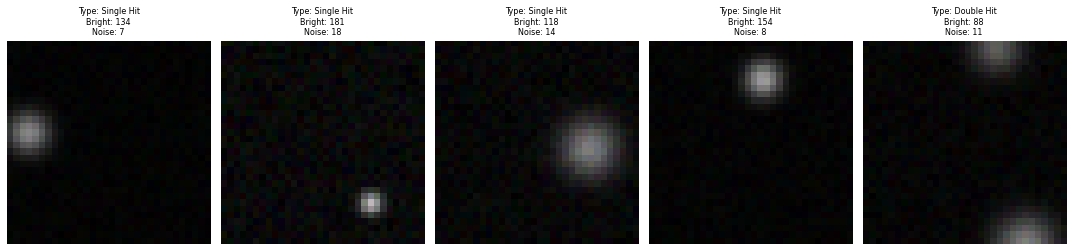

In [14]:
#  Visualize a Few Generated Events

num_to_display = min(5, len(event_data_list)) # Display up to 5 events or fewer if less generated

plt.figure(figsize=(num_to_display * 3, 4)) # Adjust figure size dynamically

for i, (image, label) in enumerate(event_data_list[:num_to_display]):
    plt.subplot(1, num_to_display, i + 1)
    plt.imshow(image)
    
    # Construct title from labels for clarity
    title_parts = [f"Type: {label['type'].replace('_', ' ').title()}"]
    if label['impacts']:
        # Show first impact's details if multiple
        first_impact = label['impacts'][0]
        title_parts.append(f"Bright: {first_impact['brightness']:.0f}")
        # title_parts.append(f"R:{first_impact['radius']:.1f}")
    title_parts.append(f"Noise: {label['noise_level']}")
    
    plt.title("\n".join(title_parts), fontsize=8)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [15]:
# Cell: Import Machine Learning Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import os
import json # To load the label dictionaries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt # For visualization

2025-07-02 15:21:13.155413: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [16]:
# Cell: Load and Preprocess the Dataset

# Define the directory where your simulated events are saved
DATASET_DIR = "simulated_events"

all_images = []
all_labels_raw = [] # To store string labels like 'single_hit', 'double_hit', 'noise_only'

print(f"Loading events from '{DATASET_DIR}'...")

# Iterate through all .npz files in the dataset directory
for filename in os.listdir(DATASET_DIR):
    if filename.endswith(".npz"):
        file_path = os.path.join(DATASET_DIR, filename)
        
        with np.load(file_path, allow_pickle=True) as data:
            image = data['image']
            labels = data['labels'].item() # .item() is needed to extract the dictionary from a 0-d array
            
            all_images.append(image)
            all_labels_raw.append(labels['type'])

print(f"Loaded {len(all_images)} events.")

# Convert lists to NumPy arrays
X = np.array(all_images, dtype=np.float32) # Images (features)
y_raw = np.array(all_labels_raw)         # Raw string labels

# --- Preprocessing ---

# 1. Normalize image pixel values to [0, 1]
# Neural networks generally perform better with normalized input
X = X / 255.0 
print(f"Image data shape after loading and normalization: {X.shape}")

# 2. Encode categorical labels (e.g., 'single_hit' -> 0, 'double_hit' -> 1, 'noise_only' -> 2)
# Then one-hot encode them (e.g., 0 -> [1, 0, 0])
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_raw)
y_one_hot = to_categorical(y_encoded)

print(f"Original labels: {np.unique(y_raw)}")
print(f"Encoded labels: {label_encoder.classes_}")
print(f"One-hot encoded label shape: {y_one_hot.shape}")

# 3. Split data into training and validation sets
# A validation set is crucial to evaluate model performance on unseen data during training
X_train, X_val, y_train, y_val = train_test_split(X, y_one_hot, test_size=0.2, random_state=42, stratify=y_encoded)

print(f"Training set size: {len(X_train)} samples")
print(f"Validation set size: {len(X_val)} samples")

Loading events from 'simulated_events'...
Loaded 1000 events.
Image data shape after loading and normalization: (1000, 32, 32, 3)
Original labels: ['double_hit' 'noise_only' 'single_hit']
Encoded labels: ['double_hit' 'noise_only' 'single_hit']
One-hot encoded label shape: (1000, 3)
Training set size: 800 samples
Validation set size: 200 samples


In [17]:
# Cell: Define the Convolutional Neural Network (CNN) Model

# Get input shape from our images (height, width, channels)
input_shape = X_train.shape[1:] 
num_classes = y_one_hot.shape[1]

print(f"Input image shape for model: {input_shape}")
print(f"Number of output classes: {num_classes}")

model = keras.Sequential([
    # Convolutional Layer 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
    layers.MaxPooling2D((2, 2)),
    
    # Convolutional Layer 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Convolutional Layer 3 (optional, for slightly deeper network)
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)), # This might make the image too small if detector_width/height are small

    # Flatten the 3D output to 1D for the Dense layers
    layers.Flatten(),
    
    # Dense (Fully Connected) Layers
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # Dropout for regularization to prevent overfitting
    layers.Dense(num_classes, activation='softmax') # Output layer for classification
])

# Compile the model
# Optimizer: Adam is a good general-purpose optimizer
# Loss: categorical_crossentropy for multi-class classification with one-hot labels
# Metrics: accuracy to monitor performance
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary() # Print a summary of the model's layers and parameters

Input image shape for model: (32, 32, 3)
Number of output classes: 3


/Users/arpanghosal/Downloads/ENTER/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159,299 (622.26 KB)

 Trainable params: 159,299 (622.26 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Cell: Train the Model

# Define training parameters
epochs = 20 # Number of times to iterate over the entire training dataset
batch_size = 32 # Number of samples per gradient update

print(f"Training model for {epochs} epochs with batch size {batch_size}...")

history = model.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    verbose=1 # Show training progress
)

print("\nModel training complete!")

Training model for 20 epochs with batch size 32...
Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.5740 - loss: 1.0091 - val_accuracy: 0.6050 - val_loss: 0.8672
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6114 - loss: 0.8578 - val_accuracy: 0.5950 - val_loss: 0.7418
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.6111 - loss: 0.7508 - val_accuracy: 0.6150 - val_loss: 0.6395
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6658 - loss: 0.6916 - val_accuracy: 0.7600 - val_loss: 0.5872
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7340 - loss: 0.6051 - val_accuracy: 0.7700 - val_loss: 0.5264
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7789 - loss: 0.5485 - val_accuracy: 0.7750 - val_loss: 0.4979
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7843 - loss: 0.5315 - val_accuracy: 0.8200 - val_loss: 0.4349
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accurac


Evaluating model on validation set...
Validation Loss: 0.3375
Validation Accuracy: 0.8650


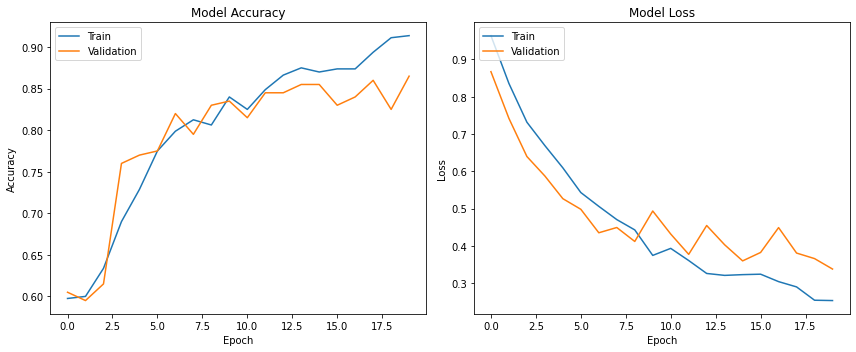


Making a few predictions on validation data:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


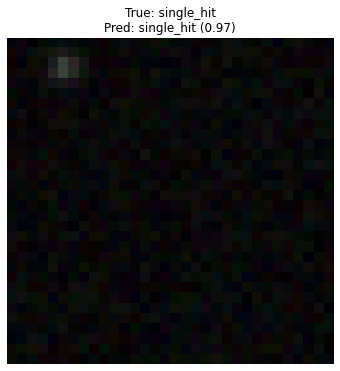

Sample 62: True Label: 'single_hit', Predicted Label: 'single_hit'
Prediction Probabilities: [0.01424929 0.01547416 0.97027653]
------------------------------
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


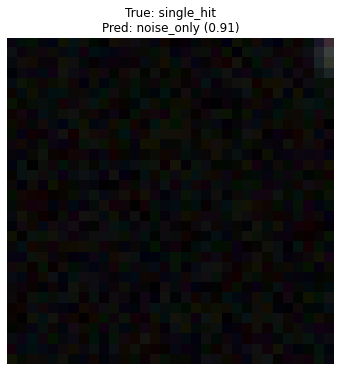

Sample 77: True Label: 'single_hit', Predicted Label: 'noise_only'
Prediction Probabilities: [3.3382964e-04 9.1085100e-01 8.8815227e-02]
------------------------------
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


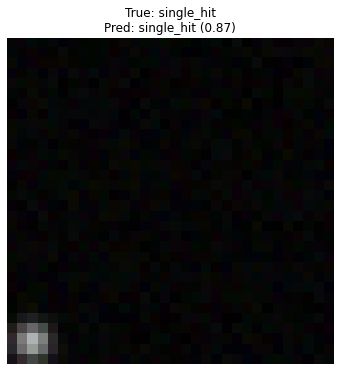

Sample 119: True Label: 'single_hit', Predicted Label: 'single_hit'
Prediction Probabilities: [1.2778203e-01 1.7971881e-10 8.7221801e-01]
------------------------------
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


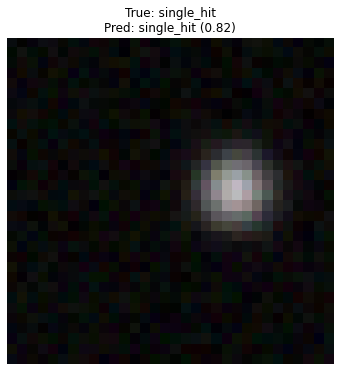

Sample 52: True Label: 'single_hit', Predicted Label: 'single_hit'
Prediction Probabilities: [1.8469936e-01 8.4513463e-22 8.1530064e-01]
------------------------------
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


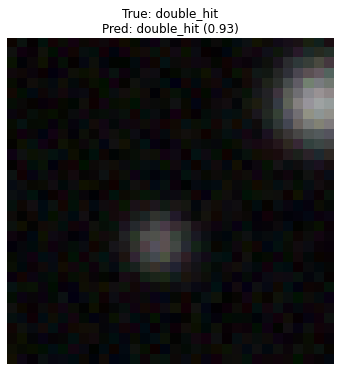

Sample 6: True Label: 'double_hit', Predicted Label: 'double_hit'
Prediction Probabilities: [9.2702144e-01 3.8802148e-19 7.2978519e-02]
------------------------------


In [20]:
# Cell: Evaluate and Visualize Training History

# Evaluate the model on the validation set
print("\nEvaluating model on validation set...")
loss, accuracy = model.evaluate(X_val, y_val, verbose=0)
print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

# Optional: Make some predictions on the validation set
print("\nMaking a few predictions on validation data:")
num_predictions = 5
random_indices = np.random.choice(len(X_val), num_predictions, replace=False)

for i in random_indices:
    sample_image = X_val[i]
    true_label_one_hot = y_val[i]
    
    # Get the predicted probabilities
    prediction_probabilities = model.predict(np.expand_dims(sample_image, axis=0))[0]
    
    # Get the predicted class index
    predicted_class_index = np.argmax(prediction_probabilities)
    true_class_index = np.argmax(true_label_one_hot)
    
    # Convert back to original string labels
    predicted_label = label_encoder.inverse_transform([predicted_class_index])[0]
    true_label = label_encoder.inverse_transform([true_class_index])[0]
    
    # Display the image
    plt.imshow(sample_image)
    plt.title(f"True: {true_label}\nPred: {predicted_label} ({prediction_probabilities[predicted_class_index]:.2f})")
    plt.axis('off')
    plt.show()

    print(f"Sample {i+1}: True Label: '{true_label}', Predicted Label: '{predicted_label}'")
    print(f"Prediction Probabilities: {prediction_probabilities}")
    print("-" * 30)